In [9]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt

In [10]:
df = pd.read_csv('../Datasets/vgsales.csv')

In [11]:
df

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [12]:
df.columns

Index(['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales',
       'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales'],
      dtype='str')

In [13]:
# Data Preparation

In [14]:
df.isnull().sum()

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [15]:
df['Year'] = df.Year.fillna(0)

In [16]:
df['Publisher'] = df.Publisher.fillna('Unknown')

In [17]:
df.isnull().sum()

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

In [18]:
df.dtypes

Rank              int64
Name                str
Platform            str
Year            float64
Genre               str
Publisher           str
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

In [19]:
df.Year = df.Year.astype('int64')

In [20]:
df.dtypes

Rank              int64
Name                str
Platform            str
Year              int64
Genre               str
Publisher           str
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

In [21]:
df

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [22]:
# Exploratory Data Analysis (EDA):

In [23]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,1973.647307,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,254.346809,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [24]:
df.columns

Index(['Rank', 'Name', 'Platform', 'Year', 'Genre', 'Publisher', 'NA_Sales',
       'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales'],
      dtype='str')

In [25]:
p = df.groupby('Platform')[['NA_Sales','EU_Sales','JP_Sales']].sum()

In [26]:
p

,NA_Sales,EU_Sales,JP_Sales
Platform,,,
2600,90.60,5.47,0.00
3DO,0.00,0.00,0.10
3DS,78.87,58.52,97.35
DC,5.43,1.69,8.56
DS,390.71,194.65,175.57
GB,114.32,47.82,85.12
GBA,187.54,75.25,47.33
GC,133.46,38.71,21.58
GEN,19.27,5.52,2.67


In [27]:
g =df.groupby('Genre')[['NA_Sales','EU_Sales','JP_Sales']].sum()

In [28]:
g

,NA_Sales,EU_Sales,JP_Sales
Genre,,,
Action,877.83,525.00,159.95
Adventure,105.80,64.13,52.07
Fighting,223.59,101.32,87.35
Misc,410.24,215.98,107.76
Platform,447.05,201.63,130.77
Puzzle,123.78,50.78,57.31
Racing,359.42,238.39,56.69
Role-Playing,327.28,188.06,352.31
Shooter,582.60,313.27,38.28


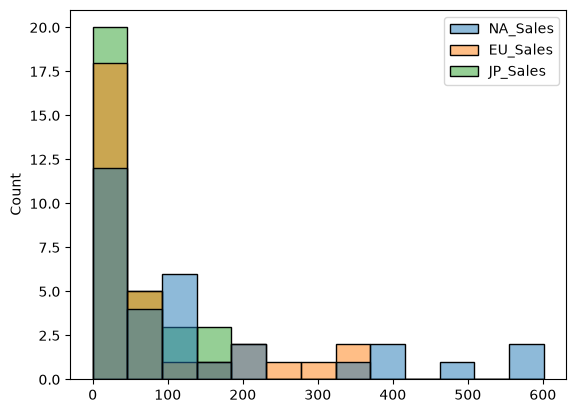

In [29]:
sb.histplot(p)
plt.show()

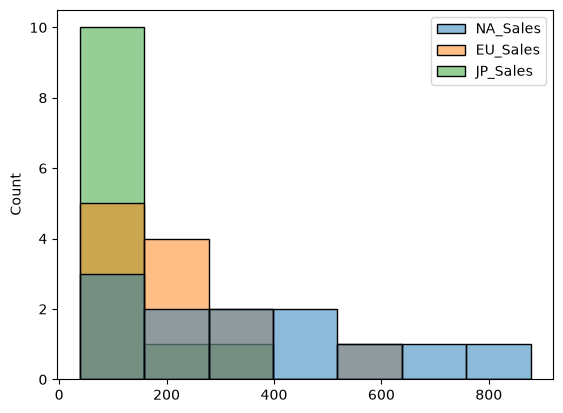

In [30]:
sb.histplot(g)
plt.show()

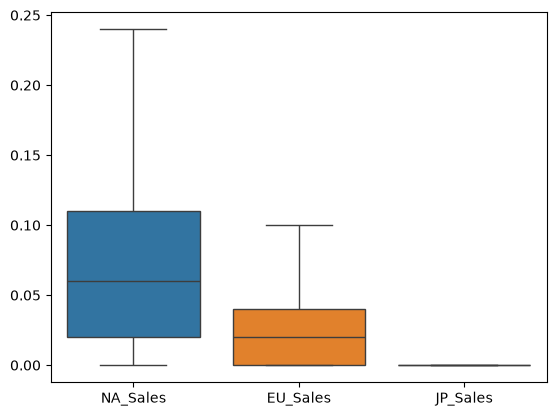

In [71]:
p = df[['NA_Sales','EU_Sales','JP_Sales']]
sb.boxplot(p)
plt.show()

In [72]:
i = 'NA_Sales'

q1 = np.percentile(df[i],25)
q3 = np.percentile(df[i],75)

iqr = q3 - q1

c1 = q1 - 1.5 * (iqr)
c2 = q3 + 1.5 * (iqr)

In [73]:
t = df[(df[i] > c2) | (df[i] < c1)]
t = t.index

In [74]:
df = df.drop(labels = t)

In [75]:
i = 'EU_Sales'

q1 = np.percentile(df[i],25)
q3 = np.percentile(df[i],75)

iqr = q3 - q1

c1 = q1 - 1.5 * (iqr)
c2 = q3 + 1.5 * (iqr)

In [76]:
t= df[(df[i] > c2) | (df[i] < c1)]
t = t.index

In [77]:
df = df.drop(labels = t)

In [78]:
i = 'JP_Sales'

q1 = np.percentile(df[i],25)
q3 = np.percentile(df[i],75)

iqr = q3 - q1

c1 = q1 - 1.5 * (iqr)
c2 = q3 + 1.5 * (iqr)

In [79]:
t= df[(df[i] > c2) | (df[i] < c1)]
t = t.index


In [80]:
df = df.drop(labels = t)

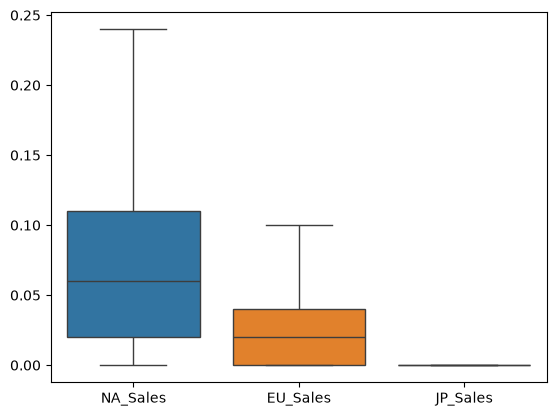

In [81]:
g = df[['NA_Sales','EU_Sales','JP_Sales']]
sb.boxplot(g)
plt.show()


In [82]:
# Top Selling Games Analysis:

In [83]:
df.sort_values('Global_Sales',ascending = False)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
1426,1428,SingStar Abba,PS2,2008,Misc,Sony Computer Entertainment,0.23,0.04,0.0,1.09,1.36
2477,2479,Ben 10: Protector of Earth,PS2,2007,Action,D3Publisher,0.09,0.00,0.0,0.74,0.84
2635,2637,Buzz! The Hollywood Quiz,PS2,2007,Misc,Sony Computer Entertainment,0.17,0.00,0.0,0.61,0.78
2731,2733,Wall-E,PS2,2008,Platform,THQ,0.21,0.00,0.0,0.54,0.75
3096,3098,Kung Fu Panda,PS2,2008,Action,Activision,0.24,0.00,0.0,0.41,0.65
...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.0,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.0,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.0,0.00,0.01
16596,16599,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.0,0.00,0.01


In [85]:
df['Global_Sales'].sum()

np.float64(740.32)

In [86]:
# Platform Performance Analysis:

In [88]:
s = df.groupby('Platform')['Global_Sales'].sum()

In [89]:
s

Platform
2600      4.81
3DS      12.57
DS       98.27
GBA      60.14
GC       42.78
N64      19.89
NES       0.06
PC       33.32
PS       52.56
PS2     107.70
PS3      40.84
PS4       6.78
PSP      31.12
PSV       5.09
Wii      75.14
WiiU      5.69
X360     63.42
XB       68.68
XOne     11.46
Name: Global_Sales, dtype: float64

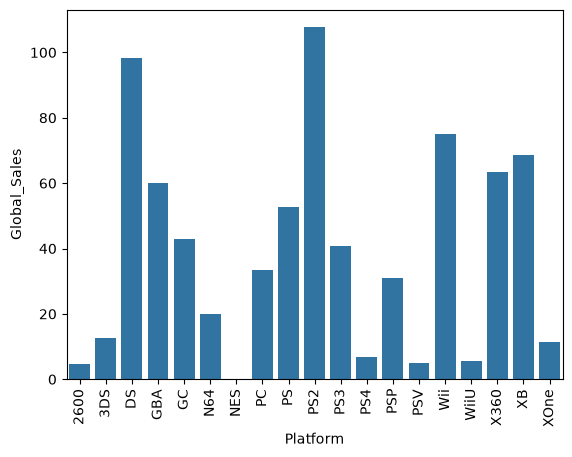

In [91]:
sb.barplot(s)
plt.xticks(rotation = 90)
plt.show()

In [92]:
# Genre Analysis:

In [94]:
y = df.groupby('Genre')['Global_Sales'].sum()

In [95]:
y

Genre
Action          158.84
Adventure        41.76
Fighting         29.44
Misc             94.30
Platform         45.78
Puzzle           24.60
Racing           70.70
Role-Playing     33.77
Shooter          59.03
Simulation       37.36
Sports          119.73
Strategy         25.01
Name: Global_Sales, dtype: float64

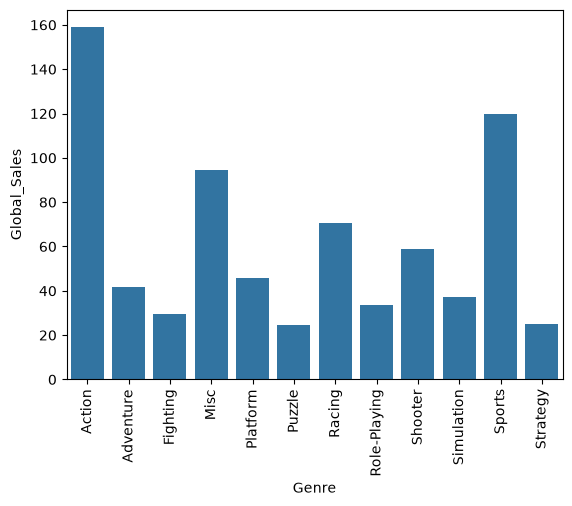

In [96]:
sb.barplot(y)
plt.xticks(rotation = 90)
plt.show()

In [98]:
df.groupby('Genre')['Year'].sum()

Genre
Action          2625753
Adventure        839209
Fighting         459066
Misc            1493562
Platform         790083
Puzzle           668319
Racing          1329554
Role-Playing     634009
Shooter         1145213
Simulation       760839
Sports          1995924
Strategy         649985
Name: Year, dtype: int64

In [99]:
# Publisher Performance Analysis:

In [100]:
df.groupby('Publisher')['Global_Sales'].sum().nlargest(10)

Publisher
Activision                      68.48
Electronic Arts                 62.09
Ubisoft                         57.19
THQ                             55.10
Sony Computer Entertainment     28.08
Konami Digital Entertainment    25.40
Atari                           24.27
Take-Two Interactive            24.09
Sega                            19.56
Midway Games                    17.24
Name: Global_Sales, dtype: float64

In [105]:
df.groupby((['Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales']))['Global_Sales'].sum()

Publisher             NA_Sales  EU_Sales  JP_Sales
10TACLE Studios       0.00      0.03      0.0         0.03
                      0.01      0.01      0.0         0.02
                      0.06      0.00      0.0         0.06
1C Company            0.00      0.01      0.0         0.01
                                0.03      0.0         0.04
                                                      ... 
iWin                  0.00      0.05      0.0         0.06
id Software           0.02      0.00      0.0         0.03
inXile Entertainment  0.02      0.06      0.0         0.10
responDESIGN          0.02      0.02      0.0         0.04
                      0.07      0.02      0.0         0.09
Name: Global_Sales, Length: 3745, dtype: float64

In [106]:
# Regional Sales:

In [109]:
a = df[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']].agg(sum)

In [110]:
a

NA_Sales       492.41
EU_Sales       177.19
JP_Sales         0.00
Other_Sales     65.71
dtype: float64

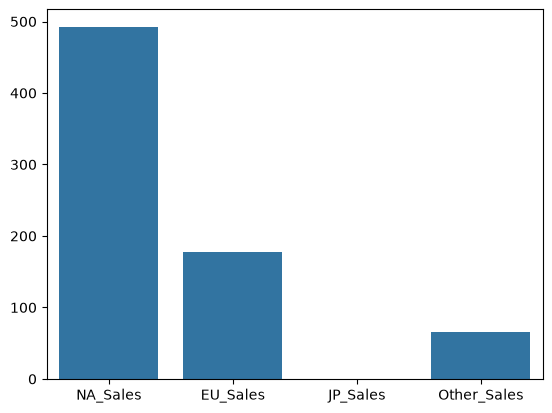

In [116]:
sb.barplot(a)
plt.show()

In [122]:
df.sort_values(['NA_Sales','EU_Sales','JP_Sales','Other_Sales'],ascending = False)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
4719,4721,Up,PSP,2009,Action,THQ,0.24,0.10,0.0,0.07,0.41
5187,5189,Spider-Man: Shattered Dimensions,X360,2010,Action,Activision,0.24,0.09,0.0,0.03,0.36
5233,5235,WWE '12,Wii,2011,Fighting,THQ,0.24,0.09,0.0,0.03,0.36
5420,5422,Herbie: Fully Loaded,GBA,2005,Racing,Disney Interactive Studios,0.24,0.09,0.0,0.01,0.34
5450,5452,Banjo-Kazooie: Grunty's Revenge,GBA,2003,Platform,THQ,0.24,0.09,0.0,0.01,0.33
...,...,...,...,...,...,...,...,...,...,...,...
16581,16584,Fit & Fun,Wii,2011,Sports,Unknown,0.00,0.01,0.0,0.00,0.01
16586,16589,Secret Files 2: Puritas Cordis,DS,2009,Adventure,Deep Silver,0.00,0.01,0.0,0.00,0.01
16596,16599,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.0,0.00,0.01
8055,8057,Summer Athletics: The Ultimate Challenge,PS2,2008,Sports,DTP Entertainment,0.00,0.00,0.0,0.18,0.18
